# Übung 7: Regionenorientierte Segmentierung

1. **Region Growing** selbst programmieren und damit die Lunge in einem CT-Bild segmentieren
2. **Connected Component Labeling (CCL)**: Buchstaben auf einem Nummernschild zählen

**Wo Sie etwas ergänzen müssen, steht `# TODO`.**

In [22]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

## 1 Region Growing

Kriterium wie in der Vorlesung: ein Nachbarpixel $p$ kommt zur Region, wenn

$$|r_p - r_\text{Seed}| \le t$$

Wir verwenden die **8er-Nachbarschaft** (alle Pixel im 3×3-Fenster um das aktuelle Pixel).

### 1.1 Bild und Seeds

Drei Seeds liegen in den beiden Lungenflügeln. Koordinaten: `[Zeile, Spalte]`.

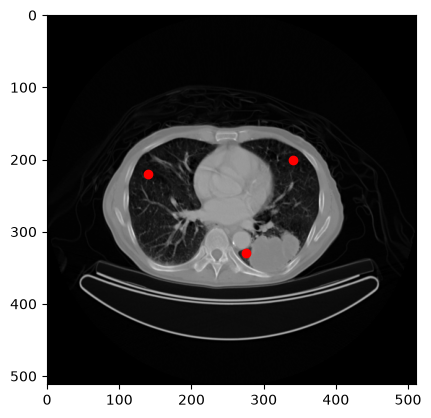

In [23]:
img = cv2.imread('CT.png', 0)
seeds = [[220, 140], [200, 340], [330, 275]]     # [Zeile, Spalte]

plt.imshow(img, cmap='gray')
plt.scatter([s[1] for s in seeds], [s[0] for s in seeds], c='r')   # scatter erwartet (x = Spalte, y = Zeile)
plt.show()

### 1.2 Algorithmus

So funktioniert der Code: In `liste` stehen die Pixel, deren Nachbarn noch geprüft werden müssen,
zusammen mit dem Grauwert ihres Seeds. Am Anfang sind das nur die Seeds.
Jeder Nachbar, der das Kriterium erfüllt, kommt in die Region **und** in die Liste.
Wenn die Liste leer ist, ist die Region fertig.

**Aufgabe:** Ergänzen Sie die drei `TODO`s.

In [28]:
def region_growing(img, seeds, t):
    seg = np.zeros(img.shape, dtype=np.uint8)
    liste = []
    for z, s in seeds:
        seg[z, s] = 255
        liste.append([z, s, int(img[z, s])])          # [Zeile, Spalte, Grauwert des Seeds]

    while liste:                                      # solange noch Pixel zu prüfen sind
        z, s, r_seed = liste.pop(0)
        for i in range(z-1, z+2):                                 # TODO: Zeilen z-1 bis z+1
            for j in range(s-1, s+2):                             # TODO: Spalten s-1 bis s+1
                if 0 <= i < img.shape[0] and 0 <= j < img.shape[1] and seg[i, j] != 255:
                    if abs(int(img[i,j])-r_seed) <= t:                           # TODO: Kriterium |r_p - r_Seed| <= t
                        seg[i, j] = 255
                        liste.append([i, j, r_seed])
    return seg


def zeige(img, seg, titel):
    plt.imshow(img, cmap='gray')
    plt.imshow(np.ma.masked_equal(seg, 0), cmap='autumn', alpha=0.5)   # Region rot über dem Bild
    plt.title(titel)
    plt.show()

*Hinweis:* `int(...)` ist nötig, weil die Grauwerte als `uint8` gespeichert sind. Ohne `int` gibt es bei `9 - 23` einen Überlauf statt −14.

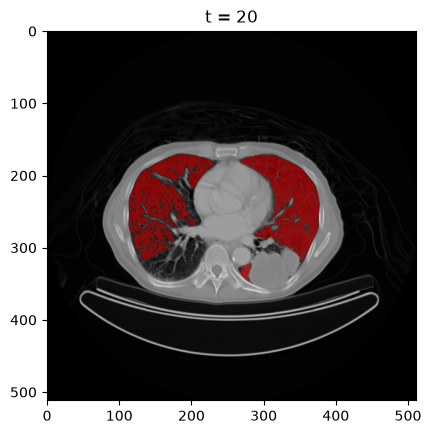

In [29]:
t = 20
seg = region_growing(img, seeds, t)
zeige(img, seg, f't = {t}')

### 1.3 Einfluss von t

**Aufgabe:** Probieren Sie $t = 5$, $t = 20$ und $t = 80$.

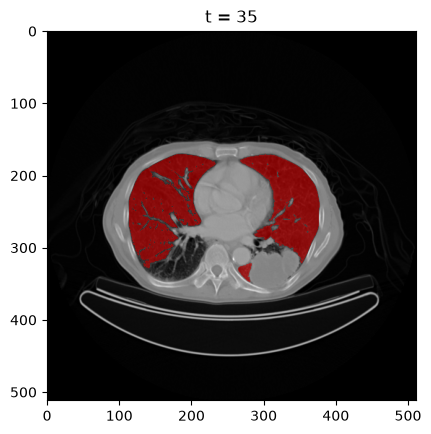

In [36]:
t = 35                                           # TODO: verschiedene Werte ausprobieren
seg = region_growing(img, seeds, t)
zeige(img, seg, f't = {t}')

*Ihre Antworten:*

1. Was passiert bei zu kleinem, was bei zu großem $t$?
- zu klein und wenig werde werden in die Region aufgenommen, heist die Region bleibt sehr klein.
- bei zu großen Werten wird alles in die Region aufgenomen und man kann nichtmehr zwischen Regionen unterscheien

### 1.4 Chaining

Jetzt vergleichen wir jeden Nachbarn nicht mit dem Seed, sondern mit dem **aktuellen Pixel**: $|r_p - r_{(z,s)}| \le t$.

**Aufgabe:** Ergänzen Sie das Kriterium und führen Sie die Zelle mit $t = 5$ und $t = 10$ aus.

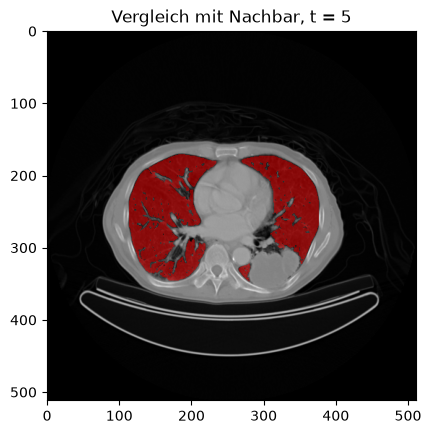

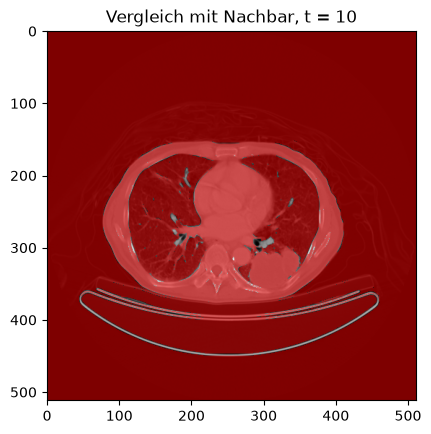

In [38]:
def region_growing_nachbar(img, seeds, t):
    seg = np.zeros(img.shape, dtype=np.uint8)
    liste = []
    for z, s in seeds:
        seg[z, s] = 255
        liste.append([z, s])

    while liste:
        z, s = liste.pop(0)
        for i in range(z - 1, z + 2):
            for j in range(s - 1, s + 2):
                if 0 <= i < img.shape[0] and 0 <= j < img.shape[1] and seg[i, j] != 255:
                    if abs(int(img[i,j]) - int(img[z,s])) <= t:                           # TODO: Kriterium mit dem aktuellen Pixel img[z, s]
                        seg[i, j] = 255
                        liste.append([i, j])
    return seg

for t in [5, 10]:
    seg = region_growing_nachbar(img, seeds, t)
    zeige(img, seg, f'Vergleich mit Nachbar, t = {t}')

*Ihre Antworten:*

2. Was passiert bei $t = 10$? Wie heißt der Effekt und warum tritt er beim Vergleich mit dem Seed nicht auf?
- bei t = 10 wird alles als Teil der Region angesehen weil sich der Wert t immer kontinuirlich ändert und aufspielt. Das nennt sich Chaining

## 2 Connected Component Labeling (CCL)

CCL ist Region Growing auf einem **Binärbild**: Alle verbundenen weißen Pixel bekommen dasselbe Label (1, 2, 3, …), der Hintergrund bekommt 0.
Damit kann man Objekte zählen.

### 2.1 Bild laden und binarisieren

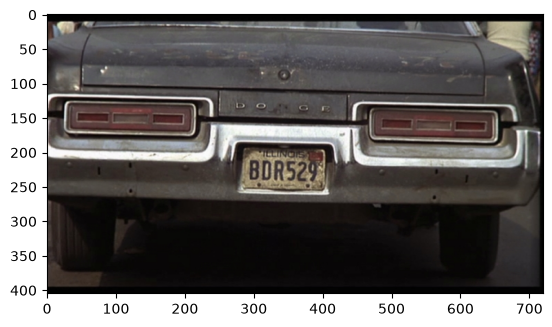

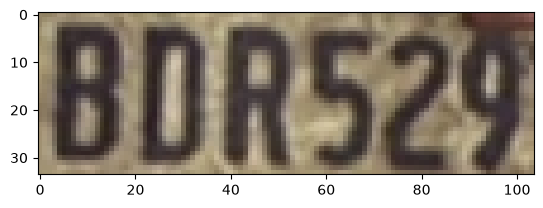

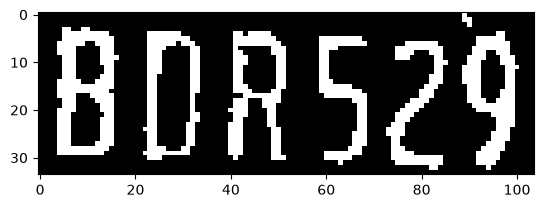

In [43]:
img = cv2.imread('bluesmobile.png')[:, :, ::-1]   # OpenCV lädt BGR, wir drehen auf RGB
plt.imshow(img)
plt.show()

schild = img[209:243, 291:395]                     # Ausschnitt: Nummernschild
img_bin = np.zeros(schild.shape[:2], dtype=np.uint8)
img_bin[schild[:, :, 0] < 70] = 255               # dunkle Buchstaben -> weiß (Objekt)

plt.imshow(schild)
plt.show()
plt.imshow(img_bin, cmap='gray')
plt.show()

### 2.2 Objekte labeln

`cv2.connectedComponentsWithStats(img_bin, connectivity=8)` gibt vier Dinge zurück:

- `n`: Anzahl der Labels **inklusive Hintergrund** (Label 0)
- `img_l`: Bild, in dem jedes Pixel sein Label enthält
- `stats`: pro Label eine Zeile, Spalte `cv2.CC_STAT_AREA` ist die Fläche in Pixeln
- `centroids`: Schwerpunkt pro Label

**Aufgabe:** Wenden Sie die Funktion an.

Anzahl Objekte: 7
Flächen: [  4 202 132 147 105 157 116]


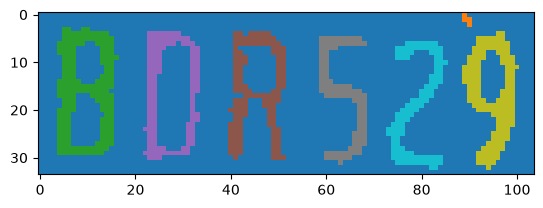

In [40]:
n, img_l, stats, centroids = cv2.connectedComponentsWithStats(img_bin, connectivity = 8)                  # TODO: cv2.connectedComponentsWithStats mit 8er-Nachbarschaft

print('Anzahl Objekte:', n - 1)
print('Flächen:', stats[1:, cv2.CC_STAT_AREA])
plt.imshow(img_l, cmap='tab10')
plt.show()

*Ihre Antworten:*

3. Wie viele Objekte findet CCL und wie viele Buchstaben hat das Schild? Woher kommt der Unterschied?
- Es sind 6 Buchstaben aber es gibt 7 Regionen; das passiert weil beim Binärbilddieser kleine Bereich auch als weiß aufgenommen wurde. Deshalb ist dies ein getrennter Bereich. Wenn man das t etwas runtersetzzen würde, dann würde dieser kleine Bereich wahrscheinlich wegfallen und dann würde es passen
nur wird bei einem kleineren t das R verschwinden, deshalb könnte man einfach vielleicht ein Closing und dann ein Opening mit mehreren Durchläufen machen, dann könnte das R stabil genug sein um das Closing zu überleben und dann würde der kleine Fleck wegfallen

### 2.3 Nachbearbeitung: kleine Objekte entfernen

**Aufgabe:** Behalten Sie nur Objekte mit mehr als 50 Pixeln und zeigen Sie jedes Zeichen einzeln an.

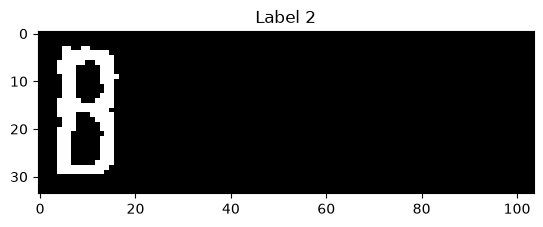

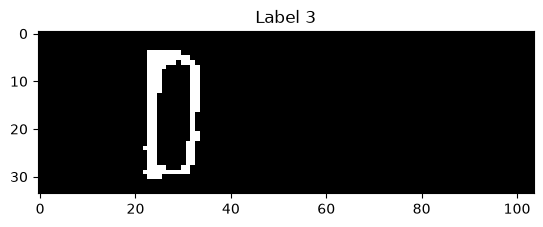

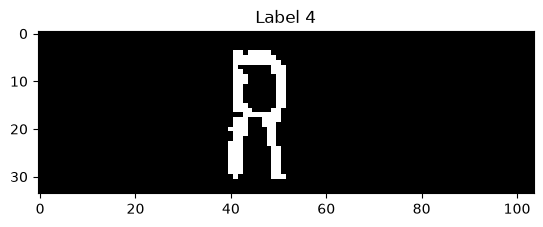

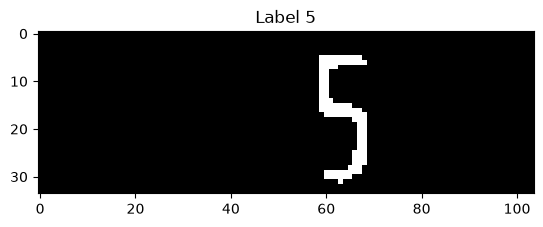

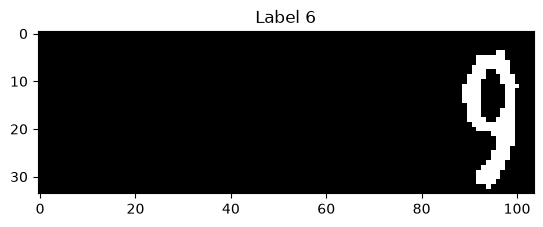

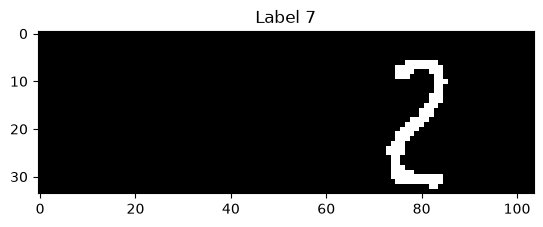

In [49]:
for i in range(1, n):                              # Label 0 ist der Hintergrund
    if stats[i, cv2.CC_STAT_AREA] > 50:                                        # TODO: Fläche von Label i größer als 50
        maske = img_l == i                                # TODO: Maske, die nur Label i enthält
        plt.imshow(maske, cmap='gray')
        plt.title(f'Label {i}')
        plt.show()